In [21]:
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

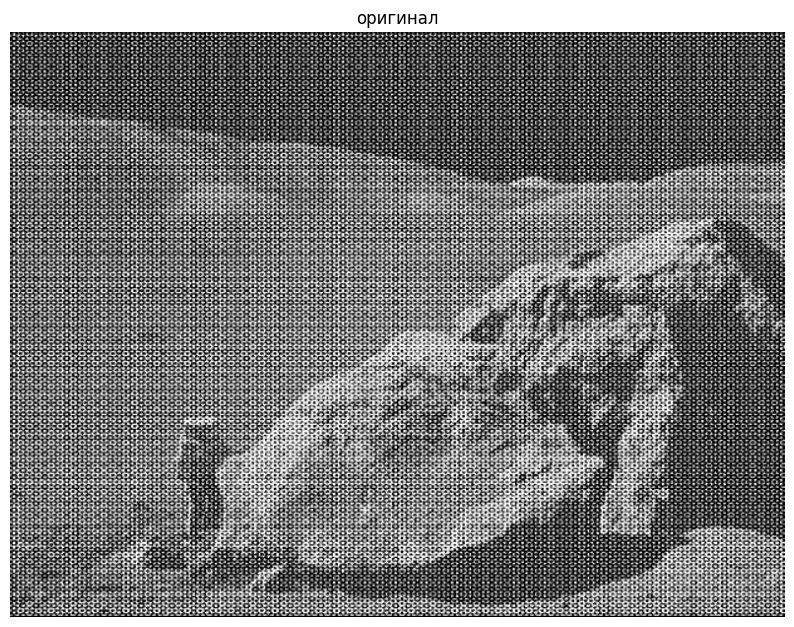

In [28]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread('periodic_noise.JPG', cv.IMREAD_GRAYSCALE)

plt.figure(figsize=(10, 8))
plt.imshow(img, cmap='gray')
plt.title("оригинал")
plt.axis('off')
plt.show()

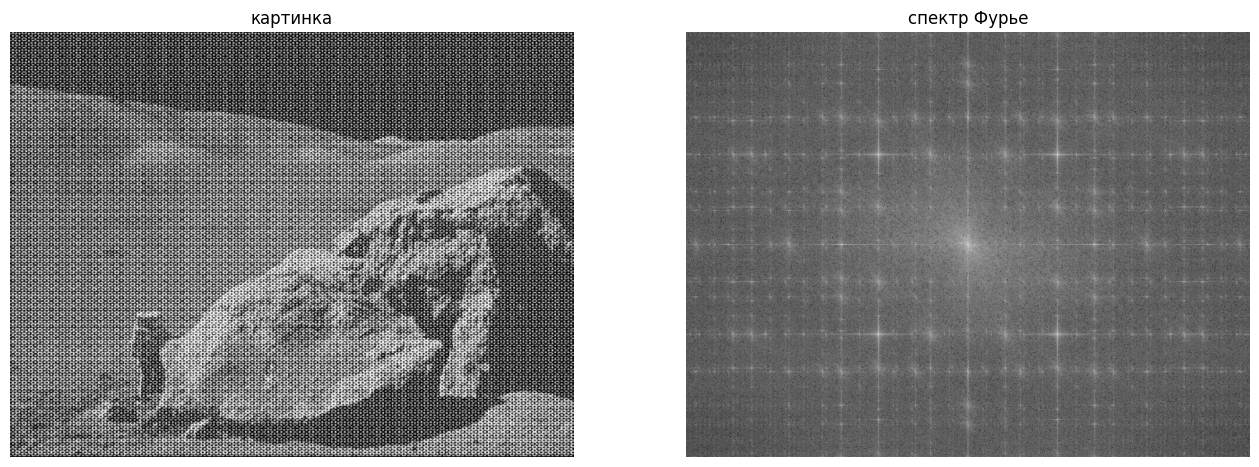

In [24]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("картинка")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("спектр Фурье")
plt.axis('off')
plt.show()

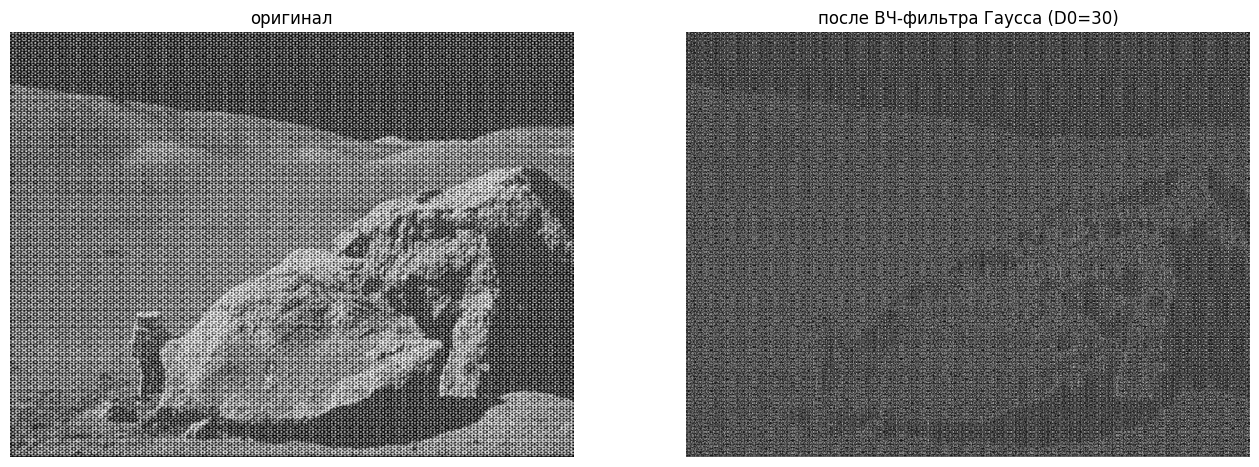

In [25]:
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2


u = np.arange(rows) - crow
v = np.arange(cols) - ccol
U, V = np.meshgrid(u, v, indexing='ij')

# гауссов ВЧ-фильтр
D0 = 30
gauss_low = np.exp(-(U**2 + V**2) / (2 * D0**2))
gauss_high = 1 - gauss_low

# применяем к спектру
dft_high = dft_shift * gauss_high[:, :, np.newaxis]

# обратное преобразование
f_ishift = np.fft.ifftshift(dft_high)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("оригинал")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_back, cmap='gray')
plt.title(f"после ВЧ-фильтра Гаусса (D0={D0})")
plt.axis('off')
plt.show()

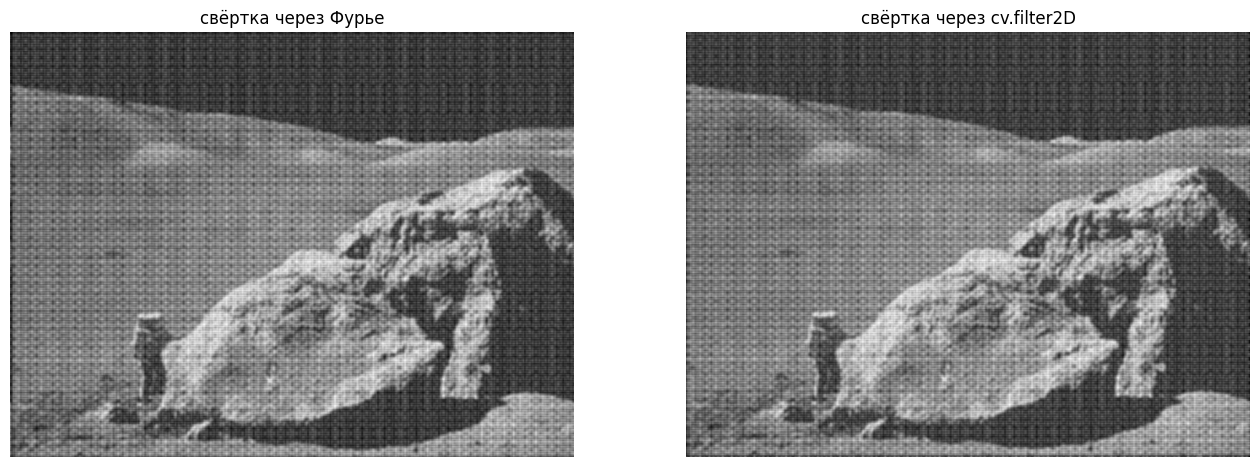

средняя разница между 2 методами: 16.584877575035772


In [26]:
kernel = np.ones((5, 5), np.float32) / 25

kernel_padded = np.zeros(img.shape, np.float32)
kernel_padded[:5, :5] = kernel

# свёртка через Фурье
img_fft = np.fft.fft2(img)
kernel_fft = np.fft.fft2(kernel_padded)
result_fft = img_fft * kernel_fft
result_spatial = np.real(np.fft.ifft2(result_fft))

# обычная свёртка через OpenCV
result_cv = cv.filter2D(img, -1, kernel)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(result_spatial, cmap='gray')
plt.title("свёртка через Фурье")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_cv, cmap='gray')
plt.title("свёртка через cv.filter2D")
plt.axis('off')
plt.show()

# результаты почти одинаковые
diff = np.abs(result_spatial - result_cv).mean()
print("средняя разница между 2 методами:", diff)

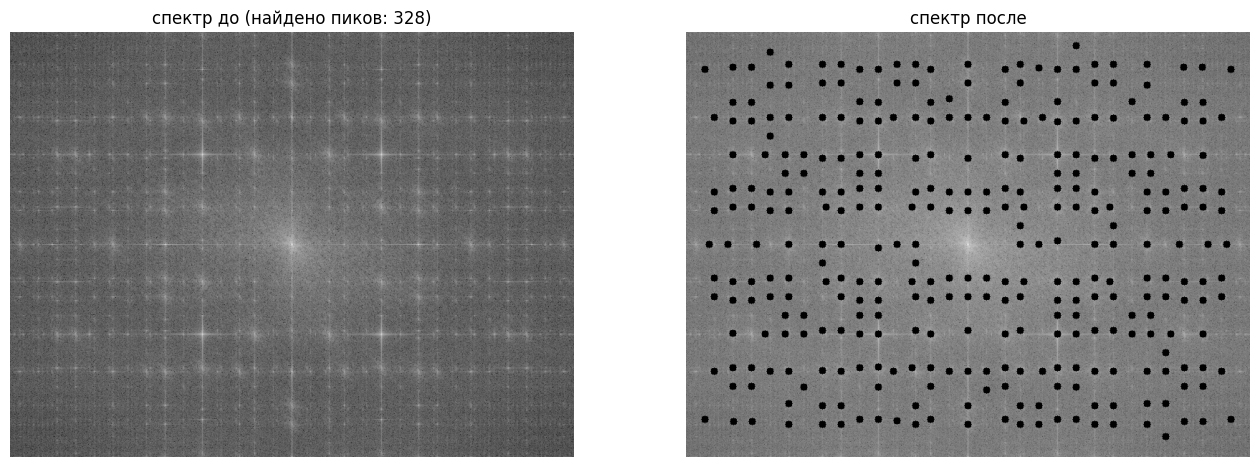

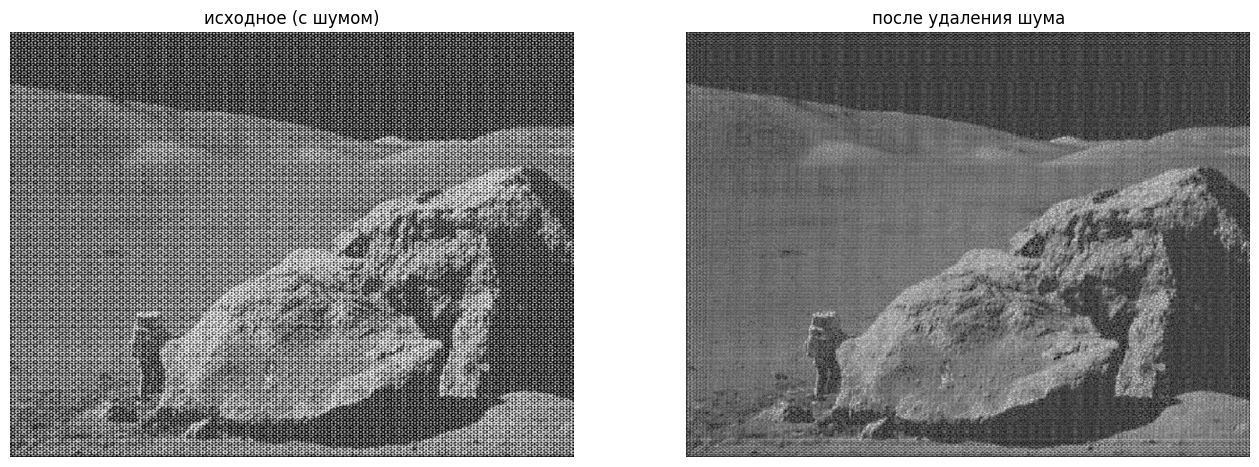

найдено пиков: 328


In [27]:
from skimage.feature import peak_local_max

# пересчитываю спектр
dft2 = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift2 = np.fft.fftshift(dft2)
magnitude_spectrum2 = 20 * np.log(cv.magnitude(dft_shift2[:, :, 0], dft_shift2[:, :, 1]) + 1)

# автомат нахожу лока макс(пики)
local_maxima = peak_local_max(magnitude_spectrum2, min_distance=20, threshold_abs=180)


mask = np.ones((rows, cols, 2), dtype=np.uint8)
for peak in local_maxima:
    y, x = peak

    distance = np.sqrt((x - ccol)**2 + (y - crow)**2)
    if distance > 40:
        cv.circle(mask, (x, y), 5, (0, 0), -1)


dft_shift_filtered = dft_shift2 * mask
magnitude_after = 20 * np.log(cv.magnitude(dft_shift_filtered[:, :, 0], dft_shift_filtered[:, :, 1]) + 1)

# обратное преобразование
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_clean = cv.idft(f_ishift)
img_clean = cv.magnitude(img_clean[:, :, 0], img_clean[:, :, 1])


plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(magnitude_spectrum2, cmap='gray')
plt.title(f"спектр до (найдено пиков: {len(local_maxima)})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_after, cmap='gray')
plt.title("спектр после")
plt.axis('off')
plt.show()

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("исходное (с шумом)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_clean, cmap='gray')
plt.title("после удаления шума")
plt.axis('off')
plt.show()

print("найдено пиков:", len(local_maxima))